<a href="https://colab.research.google.com/github/ridhima-abc/IEEE-WIE-/blob/main/spam_sms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [2]:
url = (
    "https://archive.ics.uci.edu/static/"
    "public/228/sms+spam+collection.zip"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"])

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("\nShape after cleaning:", df.shape)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Duplicate rows: 403

Shape after cleaning: (5169, 2)


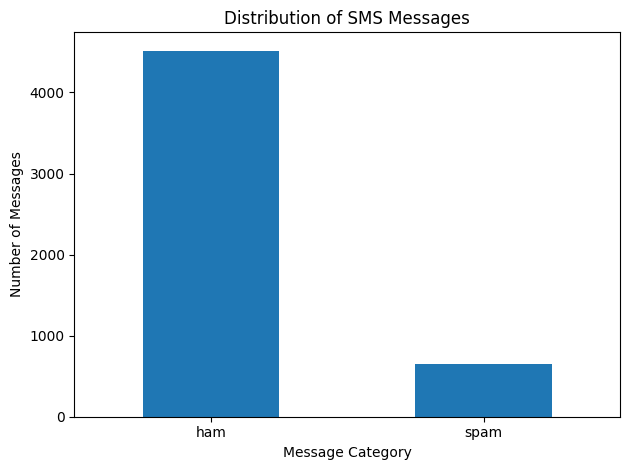

In [4]:
df["label"].value_counts().plot(
    kind="bar",
    title="Distribution of SMS Messages",
    xlabel="Message Category",
    ylabel="Number of Messages",
    rot=0
)

plt.tight_layout()
plt.show()

In [5]:
X = df["message"]
y = df["label"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [6]:
models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english"
        )),
        ("classifier", MultinomialNB())
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english"
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ])
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    print(f"\n{name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    ))



Naive Bayes
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034


Logistic Regression
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       903
        Spam       0.98      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034



                     Accuracy  Precision  Recall  F1-score
Naive Bayes            0.9671     1.0000  0.7405    0.8509
Logistic Regression    0.9565     0.9778  0.6718    0.7964


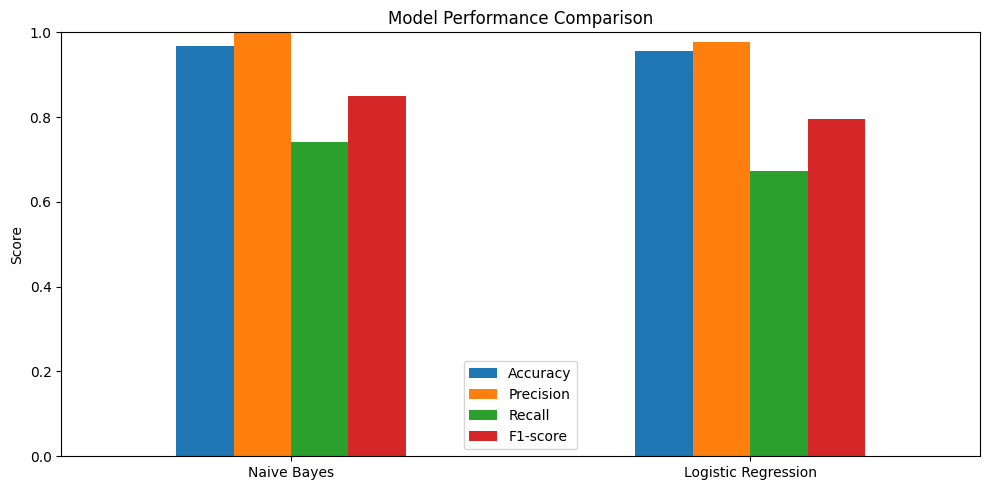

In [7]:
results_df = pd.DataFrame(results).T

print(results_df.round(4))

results_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    title="Model Performance Comparison"
)

plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

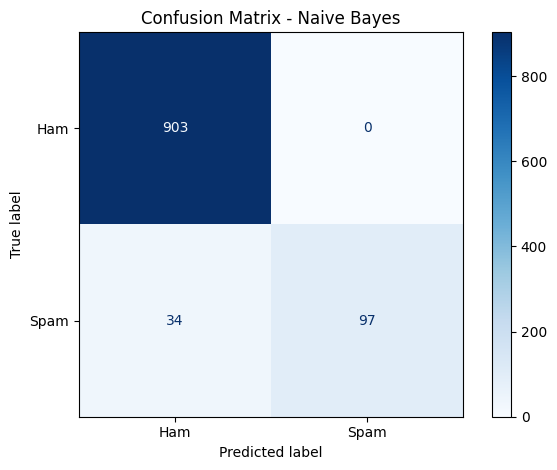

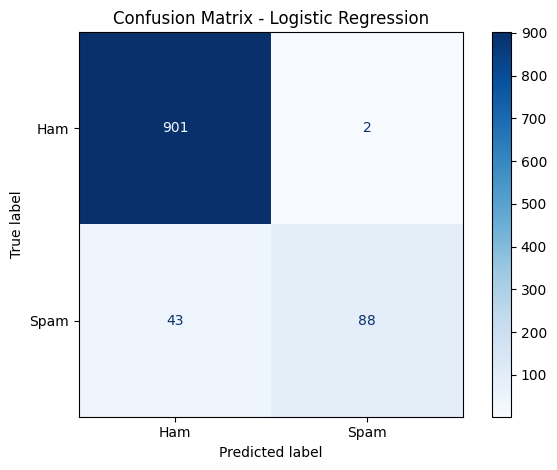

In [8]:
for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ham", "Spam"]
    )

    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [9]:
best_model_name = results_df["F1-score"].idxmax()
best_model = models[best_model_name]

test_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting at the library today?",
    "URGENT! Claim your reward by clicking this link.",
    "Please send me the notes from today's class."
]

print("Selected model:", best_model_name)

for message in test_messages:
    prediction = best_model.predict([message])[0]
    label = "SPAM" if prediction == 1 else "HAM"

    print(f"\nMessage: {message}")
    print(f"Prediction: {label}")

Selected model: Naive Bayes

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM

Message: Hey, are we meeting at the library today?
Prediction: HAM

Message: URGENT! Claim your reward by clicking this link.
Prediction: SPAM

Message: Please send me the notes from today's class.
Prediction: HAM
